# Final Ensemble — LightGBM + XGBoost (NaN Native)
## IEEE-CIS Fraud Detection | 4-Strateji Ablasyon Çalışması

**Amaç:** LightGBM ve XGBoost modellerini dört farklı kombinasyon stratejisiyle karşılaştırmak.

| Strateji | Açıklama |
|----------|----------|
| **St1** | Sadece en iyi LightGBM (GS vs V2 val'e göre seçilir) |
| **St2** | Sadece XGBoost Optuna |
| **St3** | Eşit ağırlıklı ensemble (w=0.5 / 0.5) |
| **St4** | Optimize soft voting (ağırlık val AUC-PR üzerinde taranır) |

**Pipeline:** Diğer notebook'larla tamamen özdeş (leakage-free, temporal split, NaN native).

## 1. Kütüphaneler

In [2]:
import os, gc, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import lightgbm as lgb
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_curve,
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

_t0_total = time.time()

SAVE_BASE = '/content/drive/My Drive/Bitirme/15-Mayıs-Cuma/'

print(f'LightGBM : {lgb.__version__}')
print(f'XGBoost  : {xgb.__version__}')
print(f'SAVE_BASE: {SAVE_BASE}')
print('Kutuphaneler yuklendi.')

LightGBM : 4.6.0
XGBoost  : 3.2.0
SAVE_BASE: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/
Kutuphaneler yuklendi.


## 2. Bellek Optimizasyonu

In [3]:
def reduce_mem_usage(df, verbose=True):
    start_mem = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        col_type = df[col].dtype
        if col_type == object:
            continue
        c_min, c_max = df[col].min(), df[col].max()
        if str(col_type)[:3] == 'int':
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)
        else:
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)
    end_mem = df.memory_usage(deep=True).sum() / 1024**2
    if verbose:
        print(f'Bellek: {start_mem:.1f} MB -> {end_mem:.1f} MB ({100*(start_mem-end_mem)/start_mem:.1f}% azaldi)')
    return df

## 3. Veri Yükleme

In [4]:
_t_start = time.time()

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DATA_PATH = '/content/drive/My Drive/Bitirme/VeriSeti'
df_tx = pd.read_csv(f'{DRIVE_DATA_PATH}/train_transaction.csv')
df_id = pd.read_csv(f'{DRIVE_DATA_PATH}/train_identity.csv')
df = df_tx.merge(df_id, on='TransactionID', how='left')
del df_tx, df_id; gc.collect()

df = reduce_mem_usage(df)
print(f'Veri: {df.shape[0]:,} satir x {df.shape[1]} sutun')
print(f'Fraud orani: {df.isFraud.mean()*100:.2f}%')
print(f'[SURE] Veri yukleme: {time.time()-_t_start:.1f} sn')

Mounted at /content/drive
Bellek: 2514.0 MB -> 1603.3 MB (36.2% azaldi)
Veri: 590,540 satir x 434 sutun
Fraud orani: 3.50%
[SURE] Veri yukleme: 63.0 sn


## 4. Veri Temizleme

In [5]:
_t_start = time.time()

missing_pct = df.isnull().mean()
df_clean = df.loc[:, missing_pct <= 0.80].copy()
print(f'{df.shape[1] - df_clean.shape[1]} sutun atildi (>%80 bos)')

cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna('bilinmiyor')
le = LabelEncoder()
for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))

df_clean = reduce_mem_usage(df_clean, verbose=False)
print(f'[SURE] Temizlik: {time.time()-_t_start:.1f} sn')

74 sutun atildi (>%80 bos)
[SURE] Temizlik: 9.9 sn


## 5. Zaman ve Harcama Özellikleri

In [6]:
_t_start = time.time()

df_clean['tx_hour']     = (df_clean['TransactionDT'] % 86400) // 3600
df_clean['is_night']    = ((df_clean['tx_hour'] >= 0) & (df_clean['tx_hour'] < 9)).astype(np.int8)
df_clean['tx_day']      = df_clean['TransactionDT'] // 86400
df_clean['day_of_week'] = (df_clean['TransactionDT'] // 86400) % 7
df_clean['log_amt']     = np.log1p(df_clean['TransactionAmt']).astype(np.float32)
df_clean['amt_dollars'] = df_clean['TransactionAmt'].astype(np.int32)
df_clean['amt_cents']   = ((df_clean['TransactionAmt'] % 1) * 100).round().astype(np.int8)

print(f'[SURE] Zaman ozellikleri: {time.time()-_t_start:.1f} sn')

[SURE] Zaman ozellikleri: 0.1 sn


## 6. Temporal Split (%80 Train / %20 Test)

In [7]:
_t_start = time.time()

split_idx = int(len(df_clean) * 0.80)
DROP_COLS = ['TransactionID', 'isFraud']

X_train = df_clean.iloc[:split_idx].drop(columns=DROP_COLS).copy().reset_index(drop=True)
y_train = df_clean.iloc[:split_idx]['isFraud'].reset_index(drop=True)
X_test  = df_clean.iloc[split_idx:].drop(columns=DROP_COLS).copy().reset_index(drop=True)
y_test  = df_clean.iloc[split_idx:]['isFraud'].reset_index(drop=True)

print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')
del df_clean, df; gc.collect()
print(f'[SURE] Temporal split: {time.time()-_t_start:.1f} sn')

Train: 472,432 | Test: 118,108
[SURE] Temporal split: 2.3 sn


## 7. Kronolojik Sıralama

In [8]:
_t_start = time.time()

sort_idx_train = X_train['TransactionDT'].argsort(kind='stable')
X_train = X_train.iloc[sort_idx_train].reset_index(drop=True)
y_train = y_train.iloc[sort_idx_train].reset_index(drop=True)

sort_idx_test = X_test['TransactionDT'].argsort(kind='stable')
X_test = X_test.iloc[sort_idx_test].reset_index(drop=True)
y_test = y_test.iloc[sort_idx_test].reset_index(drop=True)

print(f'Train monoton: {X_train["TransactionDT"].is_monotonic_increasing}')
print(f'Test  monoton: {X_test["TransactionDT"].is_monotonic_increasing}')
print(f'[SURE] Siralama: {time.time()-_t_start:.1f} sn')

Train monoton: True
Test  monoton: True
[SURE] Siralama: 0.7 sn


## 8. V Sütunu Seçimi (n_per_group=5)

In [9]:
_t_start = time.time()

try:
    from tqdm.auto import tqdm as _tqdm
except ImportError:
    import subprocess; subprocess.run(['pip','install','tqdm','-q'], check=True)
    from tqdm.auto import tqdm as _tqdm

def select_v_features(X_train, y_train, n_per_group=5, bucket_size=0.05, min_valid_samples=500):
    v_cols = [c for c in X_train.columns if c.startswith('V')]
    if not v_cols: return []
    missing_rates = X_train[v_cols].isnull().mean()
    buckets = (missing_rates / bucket_size).astype(int)
    selected = []
    for bucket_id in _tqdm(sorted(buckets.unique()), desc='V grup secimi'):
        cols_in_bucket = buckets[buckets == bucket_id].index.tolist()
        corr_dict = {}
        for col in cols_in_bucket:
            valid_mask = X_train[col].notna()
            if valid_mask.sum() < min_valid_samples: continue
            corr_val = abs(X_train.loc[valid_mask, col].corr(y_train[valid_mask]))
            if not np.isnan(corr_val): corr_dict[col] = corr_val
        selected.extend(sorted(corr_dict, key=corr_dict.get, reverse=True)[:n_per_group])
    return selected

all_v = [c for c in X_train.columns if c.startswith('V')]
v_selected = select_v_features(X_train, y_train, n_per_group=5)
v_drop = [c for c in all_v if c not in v_selected]
X_train.drop(columns=v_drop, inplace=True)
X_test.drop(columns=v_drop, inplace=True)
print(f'V secimi: {len(v_selected)} kaldi, {len(v_drop)} atildi.')
print(f'[SURE] V sutun secimi: {time.time()-_t_start:.1f} sn')

V grup secimi:   0%|          | 0/6 [00:00<?, ?it/s]

V secimi: 30 kaldi, 262 atildi.
[SURE] V sutun secimi: 4.3 sn


## 9. D Normalizasyonu

In [10]:
_t_start = time.time()

D_SKIP = {1,2,3,5,9}
for i in range(1,16):
    if i in D_SKIP: continue
    col = f'D{i}'
    if col not in X_train.columns: continue
    norm_col = f'{col}_norm'
    X_train[norm_col] = (X_train[col] - X_train['TransactionDT']/np.float32(86400)).astype(np.float32)
    X_test[norm_col]  = (X_test[col]  - X_test['TransactionDT'] /np.float32(86400)).astype(np.float32)

print('D normalizasyonu tamamlandi.')
print(f'[SURE] D normalizasyon: {time.time()-_t_start:.1f} sn')

D normalizasyonu tamamlandi.
[SURE] D normalizasyon: 0.0 sn


## 10. D1n ve UID

In [11]:
_t_start = time.time()

if 'D1' in X_train.columns:
    X_train['D1n'] = np.floor(X_train['tx_day'] - X_train['D1']).astype(np.float32)
    X_test['D1n']  = np.floor(X_test['tx_day']  - X_test['D1']).astype(np.float32)
else:
    X_train['D1n'] = np.nan; X_test['D1n'] = np.nan

uid_train = (X_train['card1'].astype(str)+'_'+
             X_train['addr1'].fillna(-1).astype(int).astype(str)+'_'+
             X_train['D1n'].fillna(-999).astype(int).astype(str))
uid_test  = (X_test['card1'].astype(str)+'_'+
             X_test['addr1'].fillna(-1).astype(int).astype(str)+'_'+
             X_test['D1n'].fillna(-999).astype(int).astype(str))

print(f'Benzersiz UID (train): {uid_train.nunique():,}')
print(f'[SURE] D1n ve UID: {time.time()-_t_start:.1f} sn')

Benzersiz UID (train): 182,535
[SURE] D1n ve UID: 0.7 sn


## 11. Velocity Özellikleri

In [12]:
_t_start = time.time()

X_train['_uid'] = uid_train.values; X_test['_uid'] = uid_test.values
X_train['uid_tx_count'] = X_train.groupby('_uid').cumcount().astype(np.float32)

for col, out in [('TransactionAmt','uid_amt_mean'),('TransactionAmt','uid_amt_std'),('tx_hour','uid_hour_mean')]:
    if out.endswith('_std'):
        X_train[out] = X_train.groupby('_uid')[col].transform(lambda x: x.expanding().std().shift(1)).astype(np.float32)
    else:
        X_train[out] = X_train.groupby('_uid')[col].transform(lambda x: x.expanding().mean().shift(1)).astype(np.float32)

X_train['_target'] = y_train.values
X_train['uid_fraud_mean'] = X_train.groupby('_uid')['_target'].transform(lambda x: x.expanding().mean().shift(1)).astype(np.float32)
uid_fraud_map = X_train.groupby('_uid')['_target'].mean()
X_train.drop(columns=['_target'], inplace=True)

uid_stats = X_train.groupby('_uid').agg(
    uid_amt_mean_base=('TransactionAmt','mean'), uid_amt_std_base=('TransactionAmt','std'),
    uid_hour_mean_base=('tx_hour','mean'), uid_tx_count_base=('TransactionAmt','count'))
for col, base in [('uid_tx_count','uid_tx_count_base'),('uid_amt_mean','uid_amt_mean_base'),
                  ('uid_amt_std','uid_amt_std_base'),('uid_hour_mean','uid_hour_mean_base')]:
    X_test[col] = X_test['_uid'].map(uid_stats[base]).astype(np.float32)
X_test['uid_fraud_mean'] = X_test['_uid'].map(uid_fraud_map).astype(np.float32)

X_train.drop(columns=['_uid'], inplace=True); X_test.drop(columns=['_uid'], inplace=True)
print('Velocity ozellikleri eklendi.')
print(f'[SURE] Velocity: {time.time()-_t_start:.1f} sn')

Velocity ozellikleri eklendi.
[SURE] Velocity: 180.6 sn


## 12. UID Agregasyonlar ve M Ortalamaları

In [13]:
_t_start = time.time()

X_train['_uid'] = uid_train.values; X_test['_uid'] = uid_test.values

uid_agg = X_train.groupby('_uid').agg(
    uid_mean_amt=('TransactionAmt','mean'), uid_std_amt=('TransactionAmt','std'),
    uid_count=('TransactionAmt','count'), uid_max_amt=('TransactionAmt','max'))
if 'card2' in X_train.columns:
    uid_agg['uid_nunique_card2'] = X_train.groupby('_uid')['card2'].nunique()
for col in uid_agg.columns:
    X_train[col] = X_train['_uid'].map(uid_agg[col]).astype(np.float32)
    X_test[col]  = X_test['_uid'].map(uid_agg[col]).astype(np.float32)

m_cols = [c for c in X_train.columns if c.startswith('M') and c[1:].isdigit()]
for col in m_cols:
    out = f'uid_{col}_mean'
    uid_m = X_train.groupby('_uid')[col].mean()
    X_train[out] = X_train['_uid'].map(uid_m).astype(np.float32)
    X_test[out]  = X_test['_uid'].map(uid_m).astype(np.float32)

X_train.drop(columns=['_uid'], inplace=True); X_test.drop(columns=['_uid'], inplace=True)
print(f'[SURE] UID agregasyon + M ortalamalari: {time.time()-_t_start:.1f} sn')

[SURE] UID agregasyon + M ortalamalari: 6.0 sn


## 13. Tutar Ratio ve Z-Score

In [14]:
_t_start = time.time()

for df_ in [X_train, X_test]:
    if 'uid_mean_amt' in df_.columns:
        df_['amt_ratio']  = (df_['TransactionAmt'] / (df_['uid_mean_amt'] + 1e-6)).astype(np.float32)
    if 'uid_mean_amt' in df_.columns and 'uid_std_amt' in df_.columns:
        df_['amt_zscore'] = ((df_['TransactionAmt'] - df_['uid_mean_amt']) /
                             (df_['uid_std_amt'].fillna(1.0) + 1e-6)).astype(np.float32)

print('amt_ratio, amt_zscore eklendi.')
print(f'[SURE] Tutar ratio: {time.time()-_t_start:.1f} sn')

amt_ratio, amt_zscore eklendi.
[SURE] Tutar ratio: 0.0 sn


## 14. UID Target Encoding (Val Split'ten ÖNCE)

In [15]:
_t_start = time.time()

X_train['_uid'] = uid_train.values; X_test['_uid'] = uid_test.values
X_train['_target'] = y_train.values

X_train['uid_target_enc'] = (X_train.groupby('_uid')['_target']
    .transform(lambda x: x.expanding().mean().shift(1)).astype(np.float32))
uid_fraud_rate = X_train.groupby('_uid')['_target'].mean()
X_test['uid_target_enc'] = X_test['_uid'].map(uid_fraud_rate).astype(np.float32)

X_train.drop(columns=['_uid','_target'], inplace=True)
X_test.drop(columns=['_uid'], inplace=True)
print('UID target encoding tamamlandi.')
print(f'[SURE] UID TE: {time.time()-_t_start:.1f} sn')

UID target encoding tamamlandi.
[SURE] UID TE: 44.7 sn


## 15. Val Split (Train'in Son %20'si)

In [16]:
_t_start = time.time()

val_split_idx = int(len(X_train) * 0.80)
X_tr  = X_train.iloc[:val_split_idx].copy(); y_tr = y_train.iloc[:val_split_idx].copy()
X_val = X_train.iloc[val_split_idx:].copy(); y_val = y_train.iloc[val_split_idx:].copy()

for df_ in [X_tr, X_val, X_test]:
    if 'TransactionDT' in df_.columns:
        df_.drop(columns=['TransactionDT'], inplace=True)

print(f'X_tr : {X_tr.shape[0]:,} | X_val: {X_val.shape[0]:,} | X_test: {X_test.shape[0]:,}')
print(f'[SURE] Val split: {time.time()-_t_start:.1f} sn')

X_tr : 377,945 | X_val: 94,487 | X_test: 118,108
[SURE] Val split: 0.2 sn


## 16. Kategorik Target Encoding (Val Split'ten SONRA)

In [17]:
_t_start = time.time()

cat_te_cols = [c for c in ['card1','card4','card6','ProductCD','P_emaildomain','R_emaildomain']
               if c in X_tr.columns]
global_rate = float(y_tr.mean())

for col in cat_te_cols:
    out = f'{col}_target_enc'
    rate_map = pd.DataFrame({'_cat': X_tr[col].values, '_t': y_tr.values}).groupby('_cat')['_t'].mean()
    for df_ in [X_tr, X_val, X_test]:
        df_[out] = df_[col].map(rate_map).fillna(global_rate).astype(np.float32)

assert X_tr.shape[1] == X_val.shape[1] == X_test.shape[1]
print(f'Final ozellik sayisi: {X_tr.shape[1]}')
print(f'[SURE] Kategorik TE: {time.time()-_t_start:.1f} sn')

Final ozellik sayisi: 135
[SURE] Kategorik TE: 0.1 sn


## 17. Kayıtlı Modelleri Yükle

Eğitilmiş modeller Drive'dan yüklenir. Yeniden eğitim yapılmaz.

In [18]:
import os
import time
import joblib

SAVE_BASE = '/content/drive/My Drive/Bitirme/15-Mayıs-Cuma/'

_t_start = time.time()

lgb_gs_model     = joblib.load(SAVE_BASE + 'lgb_gs256_model.pkl')
lgb_v2_model     = joblib.load(SAVE_BASE + 'lgb_optuna_v2_model.pkl')
xgb_optuna_model = joblib.load(SAVE_BASE + 'xgb_optuna_model.pkl')

print(f'LGB GS 256    : yuklendi | best_iter={lgb_gs_model.best_iteration_}')
print(f'LGB Optuna V2 : yuklendi | best_v2_iter={lgb_v2_model.best_iteration_}')
print(f'XGB Optuna    : yuklendi | best_iter={xgb_optuna_model.best_iteration}')
print(f'[SURE] Model yukleme: {time.time()-_t_start:.1f} sn')

LGB GS 256    : yuklendi | best_iter=2958
LGB Optuna V2 : yuklendi | best_v2_iter=2106
XGB Optuna    : yuklendi | best_iter=2998
[SURE] Model yukleme: 8.5 sn


## 18. Val Tahminleri ve En İyi LGB Seçimi

Val AUC-PR karşılaştırmasıyla LGB GridSearch ve LGB Optuna V2 arasından en iyi model seçilir.
Tüm sonraki stratejiler bu seçilen LGB modeli kullanır.

In [19]:
_t_start = time.time()

# ── Val tahminleri ────────────────────────────────────────────────────────────
val_proba_lgb_gs = lgb_gs_model.predict_proba(X_val)[:, 1]
val_proba_lgb_v2 = lgb_v2_model.predict_proba(X_val)[:, 1]
val_proba_xgb    = xgb_optuna_model.predict_proba(X_val)[:, 1]

# ── Test tahminleri ───────────────────────────────────────────────────────────
test_proba_lgb_gs = lgb_gs_model.predict_proba(X_test)[:, 1]
test_proba_lgb_v2 = lgb_v2_model.predict_proba(X_test)[:, 1]
test_proba_xgb    = xgb_optuna_model.predict_proba(X_test)[:, 1]

# ── Bireysel Val AUC-PR ───────────────────────────────────────────────────────
val_aucpr_gs  = average_precision_score(y_val, val_proba_lgb_gs)
val_aucpr_v2  = average_precision_score(y_val, val_proba_lgb_v2)
val_aucpr_xgb = average_precision_score(y_val, val_proba_xgb)

print('Bireysel Val AUC-PR:')
print(f'  LGB GridSearch : {val_aucpr_gs:.4f}')
print(f'  LGB Optuna V2  : {val_aucpr_v2:.4f}')
print(f'  XGB Optuna     : {val_aucpr_xgb:.4f}')

# ── En iyi LGB seçimi (val'e göre) ───────────────────────────────────────────
if val_aucpr_gs >= val_aucpr_v2:
    lgb_model_name = 'LGB GridSearch'
    val_proba_lgb  = val_proba_lgb_gs
    test_proba_lgb = test_proba_lgb_gs
else:
    lgb_model_name = 'LGB Optuna V2'
    val_proba_lgb  = val_proba_lgb_v2
    test_proba_lgb = test_proba_lgb_v2

print(f'\n>>> Secilen LGB modeli: {lgb_model_name} <<<')
print(f'[SURE] Tahmin: {time.time()-_t_start:.1f} sn')

Bireysel Val AUC-PR:
  LGB GridSearch : 0.8555
  LGB Optuna V2  : 0.8559
  XGB Optuna     : 0.8375

>>> Secilen LGB modeli: LGB Optuna V2 <<<
[SURE] Tahmin: 105.4 sn


## 19. St4 — Ağırlık Optimizasyonu (Val Üzerinde)

LGB ağırlığı 0.05–0.95 arasında taranır. En yüksek Val AUC-PR veren ağırlık St4 için seçilir.

In [20]:
_t_start = time.time()

weights = np.arange(0.05, 1.00, 0.05)
best_w_lgb, best_st4_val = 0.5, 0.0

for w in weights:
    ens_val = w * val_proba_lgb + (1 - w) * val_proba_xgb
    score   = average_precision_score(y_val, ens_val)
    if score > best_st4_val:
        best_st4_val, best_w_lgb = score, w

print(f'St4 optimal agirlik: w_lgb={best_w_lgb:.2f}, w_xgb={1-best_w_lgb:.2f}')
print(f'St4 Val AUC-PR     : {best_st4_val:.4f}')
print(f'[SURE] Agirlik optimizasyonu: {time.time()-_t_start:.1f} sn')

St4 optimal agirlik: w_lgb=0.95, w_xgb=0.05
St4 Val AUC-PR     : 0.8516
[SURE] Agirlik optimizasyonu: 0.4 sn


## 20. 4 Strateji — Test Metrikleri

In [21]:
_t_start = time.time()

# ── 4 strateji test probabiliteleri ──────────────────────────────────────────
test_proba_st1 = test_proba_lgb                                             # Sadece LGB
test_proba_st2 = test_proba_xgb                                             # Sadece XGB
test_proba_st3 = 0.5 * test_proba_lgb + 0.5 * test_proba_xgb              # Esit agirlik
test_proba_st4 = best_w_lgb * test_proba_lgb + (1-best_w_lgb)*test_proba_xgb  # Optimize

val_proba_st3  = 0.5 * val_proba_lgb + 0.5 * val_proba_xgb
val_proba_st4  = best_w_lgb * val_proba_lgb + (1-best_w_lgb) * val_proba_xgb

strategies = [
    ('St1  Sadece LGB',       val_proba_lgb,  test_proba_st1),
    ('St2  Sadece XGB',       val_proba_xgb,  test_proba_st2),
    ('St3  Esit (0.5/0.5)',   val_proba_st3,  test_proba_st3),
    ('St4  Optimize Voting',  val_proba_st4,  test_proba_st4),
]

print('=' * 68)
print(f'  4 STRATEJİ — TEST METRİKLERİ   (LGB = {lgb_model_name})')
print('=' * 68)
print(f'  {"Strateji":<28} {"Val AUC-PR":>10} {"Test AUC-PR":>11} {"Test ROC":>9}')
print('  ' + '-'*60)

results = []
for name, val_p, test_p in strategies:
    v = average_precision_score(y_val,  val_p)
    t = average_precision_score(y_test, test_p)
    r = roc_auc_score(y_test, test_p)
    results.append((name, v, t, r, test_p))
    print(f'  {name:<28} {v:>10.4f} {t:>11.4f} {r:>9.4f}')

print('=' * 68)

best_test_aucpr = max(r[2] for r in results)
winner_name = [r[0] for r in results if r[2] == best_test_aucpr][0]
print(f'\n  >>> En iyi Test AUC-PR: {winner_name.strip()} ({best_test_aucpr:.4f}) <<<')
print(f'[SURE] Test metrikler: {time.time()-_t_start:.1f} sn')

  4 STRATEJİ — TEST METRİKLERİ   (LGB = LGB Optuna V2)
  Strateji                     Val AUC-PR Test AUC-PR  Test ROC
  ------------------------------------------------------------
  St1  Sadece LGB                  0.8559      0.6307    0.9179
  St2  Sadece XGB                  0.8375      0.6005    0.9075
  St3  Esit (0.5/0.5)              0.8460      0.6137    0.9097
  St4  Optimize Voting             0.8516      0.6256    0.9139

  >>> En iyi Test AUC-PR: St1  Sadece LGB (0.6307) <<<
[SURE] Test metrikler: 0.3 sn


## 21. Eşik Analizi — St4 (Optimize Voting)

In [22]:
_t_start = time.time()
RECALL_TARGET = 0.85

def f_beta(prec, rec, beta=1.0):
    denom = (beta**2 * prec + rec)
    return (1 + beta**2) * prec * rec / (denom + 1e-10) if denom > 0 else 0.0

sweep_thresholds = sorted({
    0.001,0.002,0.005,0.01,0.02,0.03,0.04,0.05,
    0.07,0.10,0.15,0.20,0.25,0.30,0.35,0.40,
    0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
})

def threshold_sweep(proba, y_true):
    rows = []
    for t in sweep_thresholds:
        y_pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        prec = tp/(tp+fp+1e-10); rec = tp/(tp+fn+1e-10)
        rows.append({'Esik':t,'Recall':rec,'Precision':prec,
                     'F1':f_beta(prec,rec,1.0),'F2':f_beta(prec,rec,2.0),
                     'TP':tp,'FP':fp,'FN':fn})
    return pd.DataFrame(rows)

def find_best_at_recall(df_t, target):
    mask = df_t['Recall'] >= target
    return df_t[mask].sort_values('Precision', ascending=False).iloc[0] if mask.any() else None
def find_f2_opt(df_t):
    return df_t.sort_values('F2', ascending=False).iloc[0]

# ── Her strateji için özet ────────────────────────────────────────────────────
st_items = [
    ('St1 Sadece LGB',      test_proba_st1),
    ('St2 Sadece XGB',      test_proba_st2),
    ('St3 Esit (0.5/0.5)',  test_proba_st3),
    ('St4 Optimize Voting', test_proba_st4),
]

print('RECALL@85% DURUMU — TUM STRATEJILER')
print('=' * 72)
print(f'  {"Strateji":<24} {"R>=85?":>7} {"Esik":>6} {"Recall":>7} {"Prec":>7} {"F2-opt":>7}')
print('  ' + '-'*65)
st_thresholds = {}
for st_name, st_proba in st_items:
    df_t = threshold_sweep(st_proba, y_test)
    r85  = find_best_at_recall(df_t, RECALL_TARGET)
    f2o  = find_f2_opt(df_t)
    st_thresholds[st_name] = {'df': df_t, 'r85': r85, 'f2opt': f2o}
    if r85 is not None:
        print(f'  {st_name:<24} {"EVET":>7} {r85["Esik"]:>6.3f} {r85["Recall"]:>7.4f} {r85["Precision"]:>7.4f} {f2o["F2"]:>7.4f}')
    else:
        print(f'  {st_name:<24} {"HAYIR":>7}   —      —       —      {f2o["F2"]:>7.4f}')
print('=' * 72)

# ── St4 detay tablosu ─────────────────────────────────────────────────────────
df_thr = st_thresholds['St4 Optimize Voting']['df']
op85   = st_thresholds['St4 Optimize Voting']['r85']
op80   = find_best_at_recall(df_thr, 0.80)
f2op   = st_thresholds['St4 Optimize Voting']['f2opt']

H = f"{'Esik':>6} {'Recall':>7} {'Prec':>7} {'F1':>6} {'F2':>6} {'TP':>5} {'FP':>6} {'FN':>5}"
SEP = '-' * len(H)
print(f'\nDETAY ESIK TABLOSU — St4 (Optimize Voting)')
print(SEP); print(H); print(SEP)
for _, r in df_thr.iterrows():
    flags = []
    if abs(r['Recall']-0.85) < 0.015: flags.append('R~85')
    if r['Esik'] == f2op['Esik']: flags.append('F2-OPT')
    flag_str = ' <-- ' + '+'.join(flags) if flags else ''
    print(f"{r['Esik']:>6.3f} {r['Recall']:>7.4f} {r['Precision']:>7.4f} "
          f"{r['F1']:>6.4f} {r['F2']:>6.4f} "
          f"{int(r['TP']):>5,} {int(r['FP']):>6,} {int(r['FN']):>5,}{flag_str}")
print(SEP)

print()
print('KRITIK NOKTALAR (St4):')
for label, r in [('Recall>=0.85', op85), ('Recall>=0.80', op80), ('F2 Optimal', f2op)]:
    if r is None: print(f'  {label:<22} — ULASILAMADI')
    else: print(f'  {label:<22} esik={r["Esik"]:.3f} recall={r["Recall"]:.4f} prec={r["Precision"]:.4f} F2={r["F2"]:.4f}')
print(f'[SURE] Esik analizi: {time.time()-_t_start:.1f} sn')

RECALL@85% DURUMU — TUM STRATEJILER
  Strateji                  R>=85?   Esik  Recall    Prec  F2-opt
  -----------------------------------------------------------------
  St1 Sadece LGB             HAYIR   —      —       —       0.5914
  St2 Sadece XGB              EVET  0.005  0.8770  0.1000  0.5756
  St3 Esit (0.5/0.5)          EVET  0.002  0.8888  0.0940  0.5819
  St4 Optimize Voting        HAYIR   —      —       —       0.5950

DETAY ESIK TABLOSU — St4 (Optimize Voting)
-------------------------------------------------------
  Esik  Recall    Prec     F1     F2    TP     FP    FN
-------------------------------------------------------
 0.001  0.8374  0.1488 0.2527 0.4349 3,403 19,467   661 <-- R~85
 0.002  0.7987  0.1935 0.3115 0.4913 3,246 13,533   818
 0.005  0.7411  0.2744 0.4005 0.5530 3,012  7,965 1,052
 0.010  0.6939  0.3497 0.4650 0.5798 2,820  5,244 1,244
 0.020  0.6538  0.4261 0.5159 0.5907 2,657  3,579 1,407
 0.030  0.6366  0.4718 0.5420 0.5950 2,587  2,896 1,477 <-- F2-

## 22. PR Eğrisi — 4 Strateji Karşılaştırması

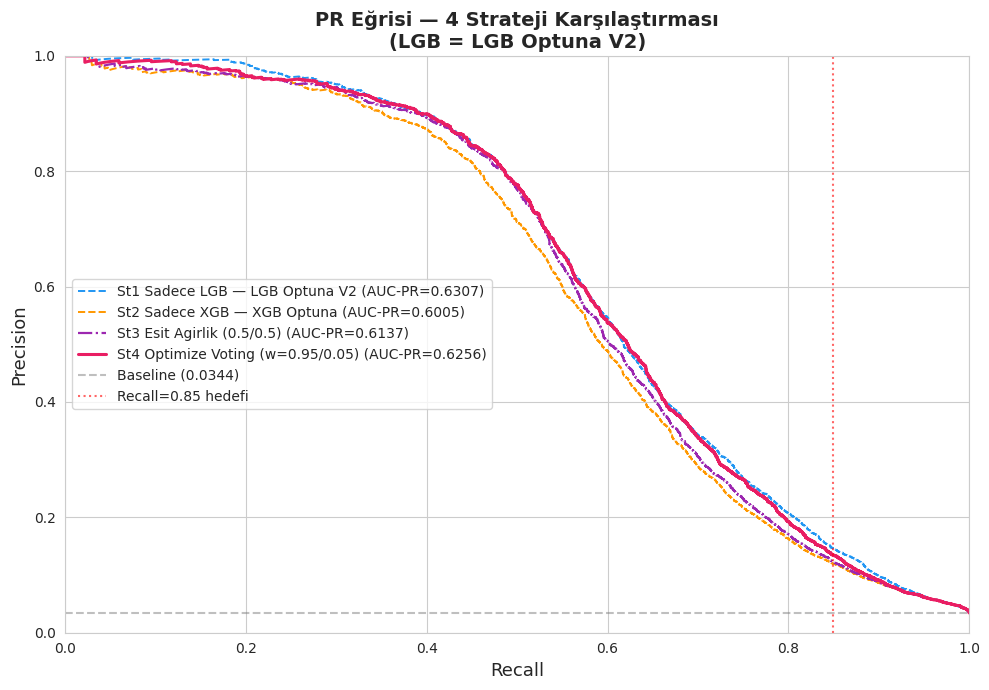

[SURE] PR egrisi: 3.3 sn


In [23]:
_t_start = time.time()

fig, ax = plt.subplots(figsize=(10, 7))
baseline = y_test.mean()

plot_items = [
    (test_proba_st1, f'St1 Sadece LGB — {lgb_model_name}',  '#2196F3', '--', 1.4),
    (test_proba_st2, 'St2 Sadece XGB — XGB Optuna',          '#FF9800', '--', 1.4),
    (test_proba_st3, 'St3 Esit Agirlik (0.5/0.5)',           '#9C27B0', '-.',  1.6),
    (test_proba_st4, f'St4 Optimize Voting (w={best_w_lgb:.2f}/{1-best_w_lgb:.2f})', '#E91E63', '-', 2.2),
]

for proba, label, color, ls, lw in plot_items:
    aucpr = average_precision_score(y_test, proba)
    prec_c, rec_c, _ = precision_recall_curve(y_test, proba)
    ax.plot(rec_c, prec_c, lw=lw, color=color, linestyle=ls,
            label=f'{label} (AUC-PR={aucpr:.4f})')

ax.axhline(y=baseline, color='gray', ls='--', alpha=0.5, label=f'Baseline ({baseline:.4f})')
ax.axvline(x=0.85, color='red', ls=':', alpha=0.6, label='Recall=0.85 hedefi')
ax.set_xlabel('Recall', fontsize=13)
ax.set_ylabel('Precision', fontsize=13)
ax.set_title(f'PR Eğrisi — 4 Strateji Karşılaştırması\n(LGB = {lgb_model_name})',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
plt.tight_layout()
plt.savefig(SAVE_BASE+'ensemble_pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'[SURE] PR egrisi: {time.time()-_t_start:.1f} sn')

## 23. St4 Ağırlık Tarama Grafiği

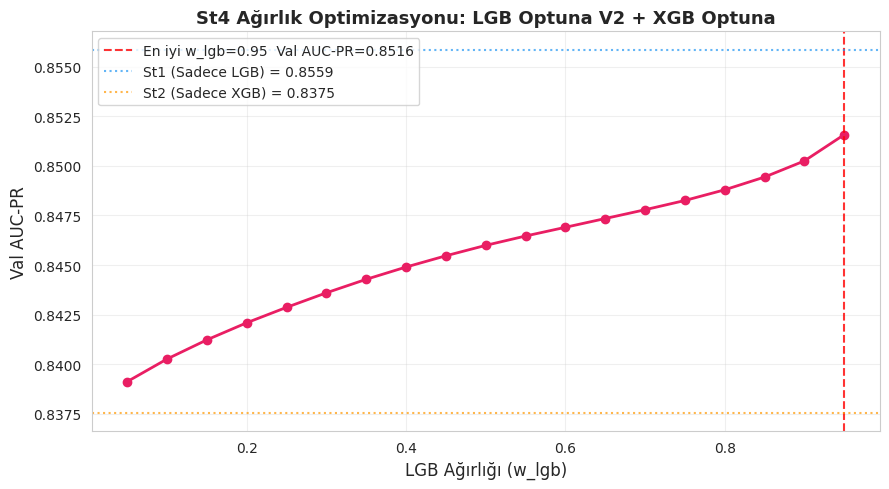

[SURE] Agirlik grafigi: 0.9 sn


In [24]:
_t_start = time.time()

fig, ax = plt.subplots(figsize=(9, 5))

scan_scores = []
for w in weights:
    ens = w * val_proba_lgb + (1-w) * val_proba_xgb
    scan_scores.append(average_precision_score(y_val, ens))

best_idx = int(np.argmax(scan_scores))
ax.plot(weights, scan_scores, 'o-', color='#E91E63', markersize=6, lw=2)
ax.axvline(x=weights[best_idx], color='red', ls='--', alpha=0.8,
           label=f'En iyi w_lgb={weights[best_idx]:.2f}  Val AUC-PR={scan_scores[best_idx]:.4f}')
ax.axhline(y=average_precision_score(y_val, val_proba_lgb), color='#2196F3',
           ls=':', alpha=0.7, label=f'St1 (Sadece LGB) = {average_precision_score(y_val, val_proba_lgb):.4f}')
ax.axhline(y=average_precision_score(y_val, val_proba_xgb), color='#FF9800',
           ls=':', alpha=0.7, label=f'St2 (Sadece XGB) = {average_precision_score(y_val, val_proba_xgb):.4f}')
ax.set_xlabel('LGB Ağırlığı (w_lgb)', fontsize=12)
ax.set_ylabel('Val AUC-PR', fontsize=12)
ax.set_title(f'St4 Ağırlık Optimizasyonu: {lgb_model_name} + XGB Optuna',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_BASE+'ensemble_weight_scan.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'[SURE] Agirlik grafigi: {time.time()-_t_start:.1f} sn')

## 24. Karşılaştırma Tablosu — 4 Strateji

In [25]:
_t_start = time.time()

print(f'{"Strateji":<32} {"Val AUC-PR":>10} {"Test AUC-PR":>11} {"Test ROC":>9}')
print('-' * 64)

best_test = max(r[2] for r in results)
for name, v, t, r, _ in results:
    marker = '  <-- EN IYI' if t == best_test else ''
    print(f'{name:<32} {v:>10.4f} {t:>11.4f} {r:>9.4f}{marker}')

print()
print('Notlar:')
print(f'  St3 vs St1/St2 : ensemble kazanci {"VAR" if results[2][2] > max(results[0][2], results[1][2]) else "YOK"}')
print(f'  St4 vs St3     : agirlik optimizasyonu kazanci {"VAR" if results[3][2] > results[2][2] else "YOK"}')
print(f'[SURE] Karsilastirma: {time.time()-_t_start:.1f} sn')

Strateji                         Val AUC-PR Test AUC-PR  Test ROC
----------------------------------------------------------------
St1  Sadece LGB                      0.8559      0.6307    0.9179  <-- EN IYI
St2  Sadece XGB                      0.8375      0.6005    0.9075
St3  Esit (0.5/0.5)                  0.8460      0.6137    0.9097
St4  Optimize Voting                 0.8516      0.6256    0.9139

Notlar:
  St3 vs St1/St2 : ensemble kazanci YOK
  St4 vs St3     : agirlik optimizasyonu kazanci VAR
[SURE] Karsilastirma: 0.0 sn


## 25. Sonuçları Kaydet

In [26]:
_t_start = time.time()
import datetime

os.makedirs(SAVE_BASE, exist_ok=True)

df_thr.to_csv(SAVE_BASE+'ensemble_threshold_table.csv', index=False)
print('  ensemble_threshold_table.csv kaydedildi.')

# Tüm 4 strateji metriklerini kaydet
names_map = {'St1  Sadece LGB':'st1','St2  Sadece XGB':'st2',
             'St3  Esit (0.5/0.5)':'st3','St4  Optimize Voting':'st4'}
flat = {}
for name, v, t, r, _ in results:
    key = names_map.get(name, name.lower().replace(' ','_'))
    flat[f'{key}_val_auc_pr']  = round(v, 4)
    flat[f'{key}_test_auc_pr'] = round(t, 4)
    flat[f'{key}_test_roc']    = round(r, 4)

# Her strateji recall@85 durumunu da kaydet
for st_name, _ in [('St1 Sadece LGB','st1'),('St2 Sadece XGB','st2'),
                   ('St3 Esit (0.5/0.5)','st3'),('St4 Optimize Voting','st4')]:
    key  = st_name.lower().split()[1]
    r85i = st_thresholds[st_name]['r85']
    flat[f'{key}_recall85_reached'] = r85i is not None

record = {
    'tarih'               : datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
    'model'               : 'Ensemble',
    'yontem'              : '4-Strateji Ablasyon (St1-St4)',
    'nan_stratejisi'      : 'NaN Native',
    'lgb_model'           : lgb_model_name,
    'xgb_model'           : 'XGB Optuna',
    'st4_w_lgb'           : round(best_w_lgb, 2),
    'st4_w_xgb'           : round(1-best_w_lgb, 2),
    **flat,
    'st4_val_test_gap'    : round(results[3][1] - results[3][2], 4),
    'prec_at_recall85'    : round(op85['Precision'], 4) if op85 is not None else None,
    'recall_at_recall85'  : round(op85['Recall'], 4)    if op85 is not None else None,
    'thr_at_recall85'     : round(op85['Esik'], 3)      if op85 is not None else None,
    'f2_at_recall85'      : round(op85['F2'], 4)        if op85 is not None else None,
    'f2_optimal_threshold': round(f2op['Esik'], 3),
    'f2_optimal_f2'       : round(f2op['F2'], 4),
    'f2_optimal_recall'   : round(f2op['Recall'], 4),
    'f2_optimal_precision': round(f2op['Precision'], 4),
    'sure_dk'             : round((time.time() - _t0_total) / 60, 1),
}

df_record = pd.DataFrame([record])
df_record.to_csv(SAVE_BASE+'ensemble_record.csv', index=False)
print('  ensemble_record.csv kaydedildi.')
print()
print('=== VERİ KAYDI ===')
for k, v in record.items():
    print(f'  {k:<34}: {v}')
print(f'[SURE] Kaydetme: {time.time()-_t_start:.1f} sn')

  ensemble_threshold_table.csv kaydedildi.
  ensemble_record.csv kaydedildi.

=== VERİ KAYDI ===
  tarih                             : 2026-06-07 16:51
  model                             : Ensemble
  yontem                            : 4-Strateji Ablasyon (St1-St4)
  nan_stratejisi                    : NaN Native
  lgb_model                         : LGB Optuna V2
  xgb_model                         : XGB Optuna
  st4_w_lgb                         : 0.95
  st4_w_xgb                         : 0.05
  st1_val_auc_pr                    : 0.8559
  st1_test_auc_pr                   : 0.6307
  st1_test_roc                      : 0.9179
  st2_val_auc_pr                    : 0.8375
  st2_test_auc_pr                   : 0.6005
  st2_test_roc                      : 0.9075
  st3_val_auc_pr                    : 0.846
  st3_test_auc_pr                   : 0.6137
  st3_test_roc                      : 0.9097
  st4_val_auc_pr                    : 0.8516
  st4_test_auc_pr                   : 0.6256
  s

## 26. Deney Özeti

In [27]:
total = time.time() - _t0_total
print('=' * 68)
print('  ENSEMBLE ABLASYON ÇALIŞMASI — ÖZET')
print('=' * 68)
print(f'  LGB Modeli : {lgb_model_name}')
print(f'  XGB Modeli : XGB Optuna')
print(f'  St4 w_lgb  : {best_w_lgb:.2f} | w_xgb: {1-best_w_lgb:.2f}')
print()
print(f'  {"Strateji":<28} {"Val AUC-PR":>10} {"Test AUC-PR":>11} {"Test ROC":>9}')
print('  ' + '-'*60)
best_test = max(r[2] for r in results)
for name, v, t, r, _ in results:
    marker = '  <-- EN IYI' if t == best_test else ''
    print(f'  {name:<28} {v:>10.4f} {t:>11.4f} {r:>9.4f}{marker}')
print()
if op85 is not None:
    print(f'  St4 Prec @ Recall>=0.85 : {op85["Precision"]:.4f}  (esik={op85["Esik"]:.3f})')
else:
    print('  St4 Recall>=0.85        : ULASILAMADI')
print()
print(f'  Toplam sure : {total/60:.1f} dakika')
print('=' * 68)

  ENSEMBLE ABLASYON ÇALIŞMASI — ÖZET
  LGB Modeli : LGB Optuna V2
  XGB Modeli : XGB Optuna
  St4 w_lgb  : 0.95 | w_xgb: 0.05

  Strateji                     Val AUC-PR Test AUC-PR  Test ROC
  ------------------------------------------------------------
  St1  Sadece LGB                  0.8559      0.6307    0.9179  <-- EN IYI
  St2  Sadece XGB                  0.8375      0.6005    0.9075
  St3  Esit (0.5/0.5)              0.8460      0.6137    0.9097
  St4  Optimize Voting             0.8516      0.6256    0.9139

  St4 Recall>=0.85        : ULASILAMADI

  Toplam sure : 7.2 dakika


In [28]:
# St3 F2-optimal satırını göster
f2_st3 = st_thresholds['St3 Esit (0.5/0.5)']['f2opt']
print(f"\nSt3 F2-Optimal:")
print(f"  Esik     : {f2_st3['Esik']:.3f}")
print(f"  Recall   : {f2_st3['Recall']:.4f}")
print(f"  Precision: {f2_st3['Precision']:.4f}")
print(f"  F2       : {f2_st3['F2']:.4f}")


St3 F2-Optimal:
  Esik     : 0.150
  Recall   : 0.6284
  Precision: 0.4489
  F2       : 0.5819
